Linear Regression – Programming Assignment - Part 1

Shervin Mihankhah 404422173

## Execution instructions
this file uses jupiter, a requirements.txt file has been prepared.
python -m pip install jupyter numpy pandas matplotlib seaborn, place cars.csv beside the notebook, and select Restart Kernel and Run All Cells. notebook writes used_cars_results.csv and used_cars_rmse.png

## Describe the dataset and columns

**this is the used dataset**
Used car price https://www.kaggle.com/datasets/lepchenkov/usedcarscatalog
The following data dictionary covers the supplied fields. Meanings follow the names and dataset context.
| Column | Meaning and role |
|---|---|
| manufacturer_name | Manufacturer category  |
| model_name | car model category  |
| transmission | Transmission category  |
| color |  color category  |
| odometer_value | Recorded mileage, interpreted as kilometres, selected predictor |
| year_produced | Production year, selected predictor |
| engine_fuel | Fuel category r |
| engine_has_gas | Flag for a gas fuel |
| engine_type | Engine type category  |
| engine_capacity | Engine capacity, interpreted as litres, selected predictor |
| body_type | Body style category  |
| has_warranty | Warranty flag |
| state | Listed vehicle condition/status category |
| drivetrain | Driven-wheel configuration |
| price_usd | Advertised price in USD, regression target |
| is_exchangeable | Flag indicating exchange is accepted |
| location_region | Listing region |
| number_of_photos | Listing photo count |
| up_counter | Listing promotion counter  |
| feature_0 through feature_9 |   exact meanings unspecified |
| duration_listed | Listing duration  |






In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt



df = pd.read_csv('cars.csv')
target = 'price_usd'
features = ['odometer_value', 'year_produced', 'engine_capacity']

display(df.head())
print("Missing values:")
print(df[features + [target]].isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nSummary statistics:")
# display(df[features + [target]].describe())
display(df.describe())

,manufacturer_name,model_name,transmission,color,odometer_value,year_produced,engine_fuel,engine_has_gas,engine_type,engine_capacity,...,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,duration_listed
0,Subaru,Outback,automatic,silver,190000,2010,gasoline,False,gasoline,2.5,...,True,True,True,False,True,False,True,True,True,16
1,Subaru,Outback,automatic,blue,290000,2002,gasoline,False,gasoline,3.0,...,True,False,False,True,True,False,False,False,True,83
2,Subaru,Forester,automatic,red,402000,2001,gasoline,False,gasoline,2.5,...,True,False,False,False,False,False,False,True,True,151
3,Subaru,Impreza,mechanical,blue,10000,1999,gasoline,False,gasoline,3.0,...,False,False,False,False,False,False,False,False,False,86
4,Subaru,Legacy,automatic,black,280000,2001,gasoline,False,gasoline,2.5,...,True,False,True,True,False,False,False,False,True,7


Missing values:
odometer_value      0
year_produced       0
engine_capacity    10
price_usd           0
dtype: int64

Duplicate rows: 40

Summary statistics:


,odometer_value,year_produced,engine_capacity,price_usd,number_of_photos,up_counter,duration_listed
count,38531.000000,38531.000000,38521.000000,38531.000000,38531.000000,38531.000000,38531.000000
mean,248864.638447,2002.943734,2.055161,6639.971021,9.649062,16.306091,80.577249
std,136072.376530,8.065731,0.671178,6428.152018,6.093217,43.286933,112.826569
min,0.000000,1942.000000,0.200000,1.000000,1.000000,1.000000,0.000000
25%,158000.000000,1998.000000,1.600000,2100.000000,5.000000,2.000000,23.000000
50%,250000.000000,2003.000000,2.000000,4800.000000,8.000000,5.000000,59.000000
75%,325000.000000,2009.000000,2.300000,8990.000000,12.000000,16.000000,91.000000
max,1000000.000000,2019.000000,8.000000,50000.000000,86.000000,1861.000000,2232.000000


In [3]:
print(df.shape)

(38531, 30)


##  Univariate Analysis
Look at whe target distribution, mileage outliers and transmission frequencies. An outlier deserves investigation before removal.

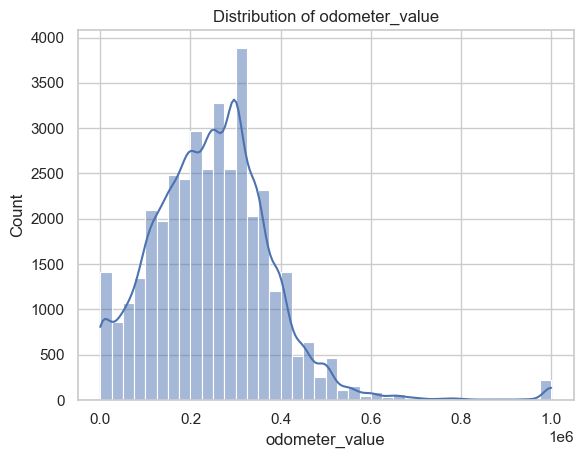

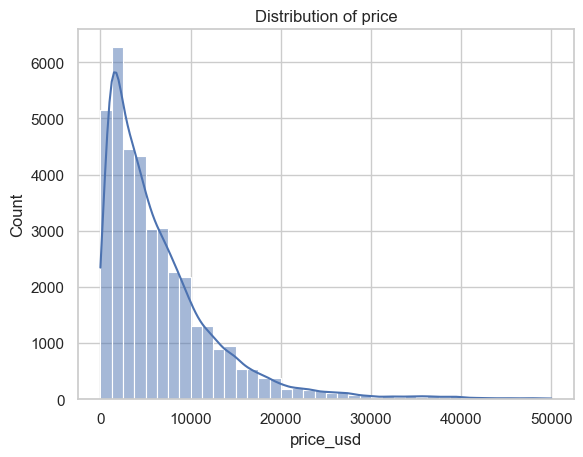

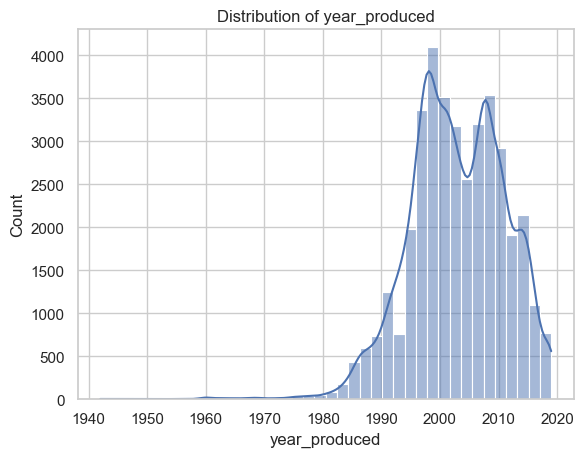

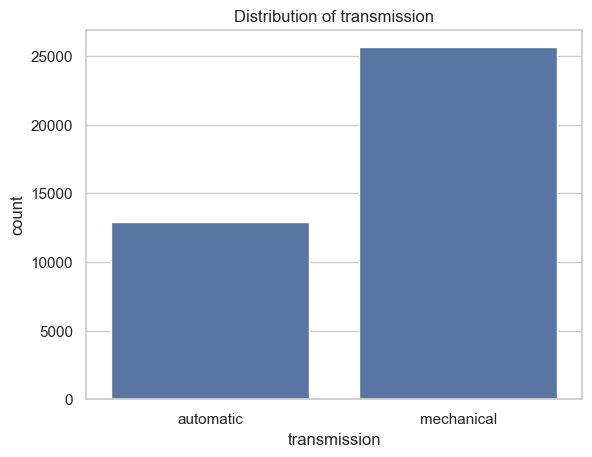

In [4]:
sns.set_theme(style='whitegrid')

sns.histplot(df['odometer_value'], kde=True, bins=40)
plt.title('Distribution of odometer_value')
plt.show()


sns.histplot(df['price_usd'], kde=True, bins=40)
plt.title('Distribution of price')
plt.show()


sns.histplot(df['year_produced'], kde=True, bins=40)
plt.title('Distribution of year_produced')
plt.show()


sns.countplot(x='transmission', data=df)
plt.title('Distribution of transmission')
plt.show()

##  Bivariate Analysis
Inspect how price varies with production year and transmission. Correlation describes association within this dataset.

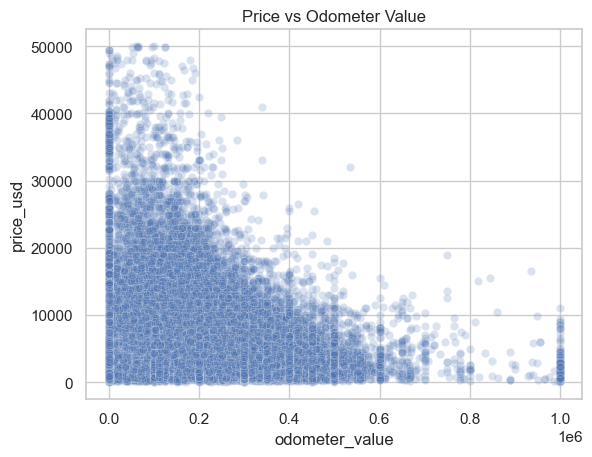

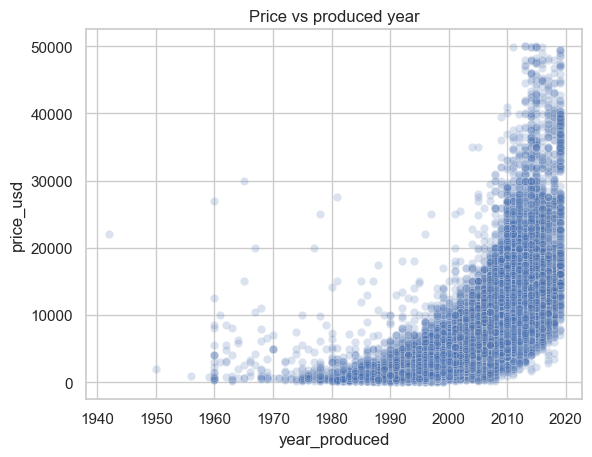

Correlation between year and price 0.7055105380169359


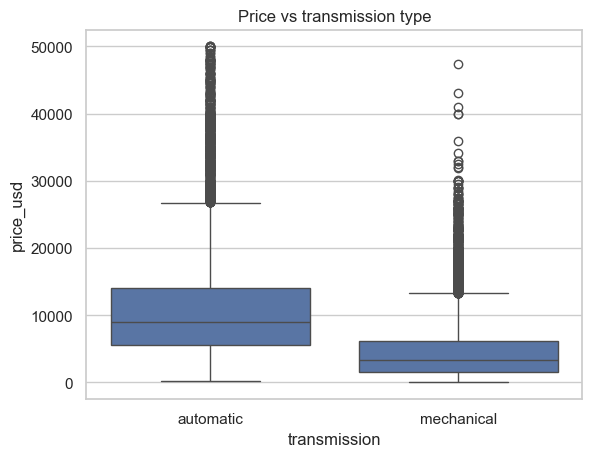

In [5]:
sns.scatterplot(x='odometer_value', y='price_usd', data=df, alpha=0.2)
plt.title('Price vs Odometer Value')
plt.show()


sns.scatterplot(x='year_produced', y='price_usd', data=df, alpha=0.2)
plt.title('Price vs produced year')
plt.show()

year_price_corr = df['year_produced'].corr(df['price_usd'])

print('Correlation between year and price', year_price_corr)

# 
sns.boxplot(x='transmission', y='price_usd', data= df)
plt.title('Price vs transmission type')
plt.show()

## Multivariate Analysis
analysis the pair plot.

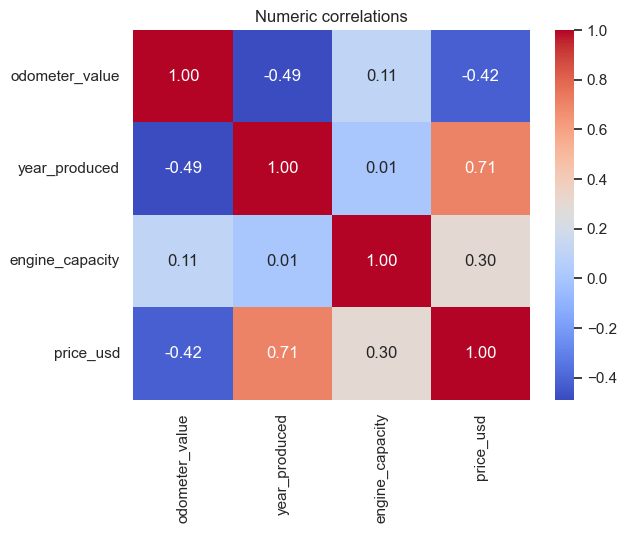

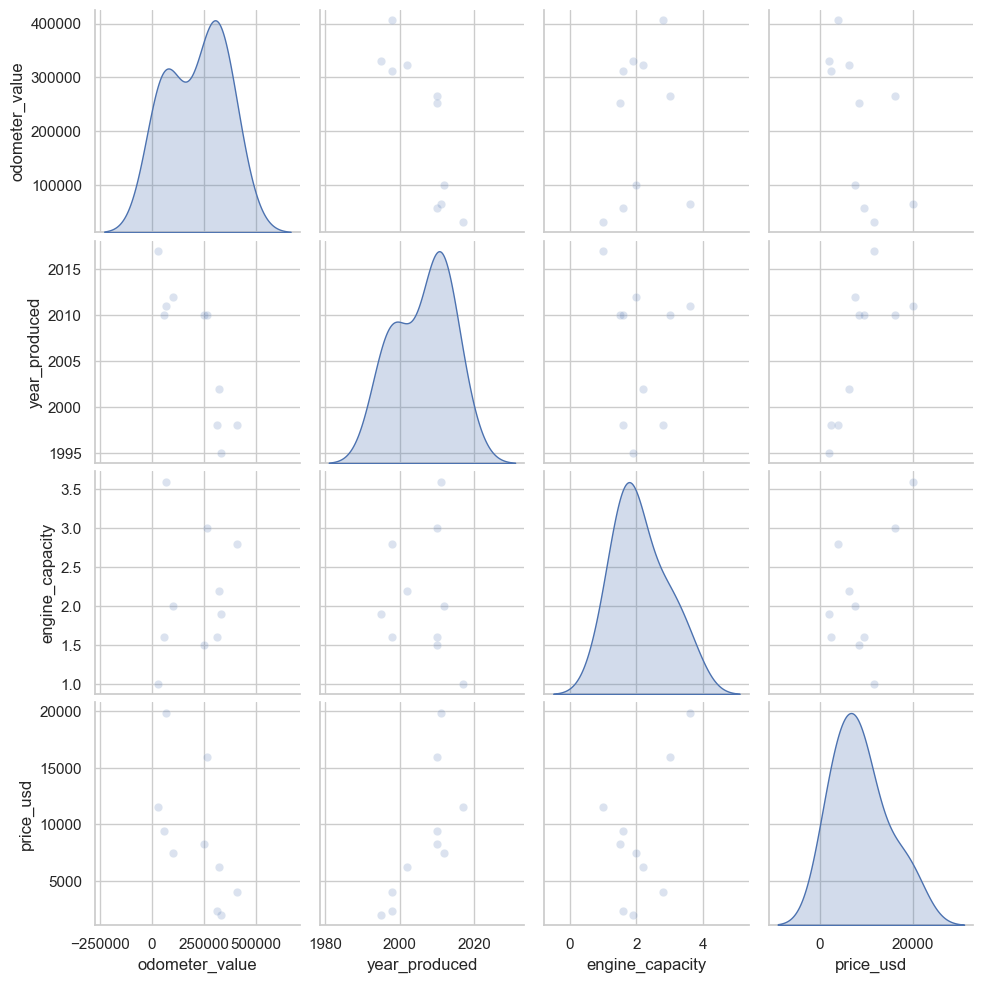

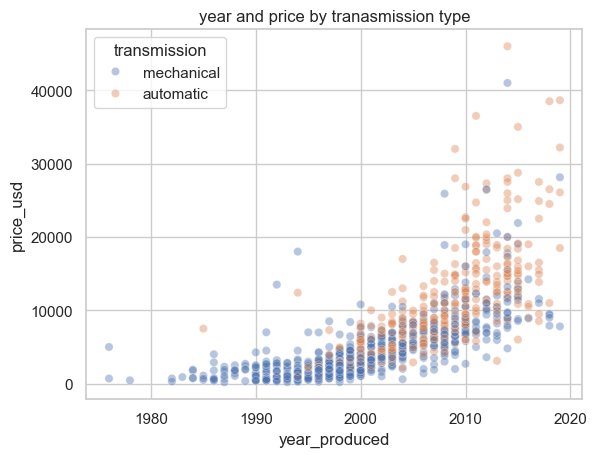

In [ ]:
eda_columns = ['odometer_value', 'year_produced', 'engine_capacity', 'price_usd']
sns.heatmap(df[eda_columns].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Numeric correlations')
plt.show()


sns.pairplot(df[eda_columns].sample(1000, random_state=42), diag_kind='kde', plot_kws={'alpha':0.2})
plt.show()


sns.scatterplot(x='year_produced', y ='price_usd', hue= 'transmission', data = df.sample(1000, random_state= 42), alpha = 0.4)
plt.title('year and price by tranasmission type')
plt.show()



# Preprocessing
## Choose the target and predictors

In [7]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from itertools import combinations_with_replacement



df = pd.read_csv('cars.csv')
target = 'price_usd'
features = ['odometer_value', 'year_produced', 'engine_capacity']
DEGREES = [1, 2, 3, 4, 5]
SEED = 42

display(df.head())
print("Missing values:")
print(df[features + [target]].isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nSummary statistics:")
# display(df[features + [target]].describe())
display(df.describe())

display(pd.DataFrame({'type': df.dtypes.astype(str),
                      'missing_values': df.isna().sum(),
                      'distinct_values': df.nunique()}))

,manufacturer_name,model_name,transmission,color,odometer_value,year_produced,engine_fuel,engine_has_gas,engine_type,engine_capacity,...,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,duration_listed
0,Subaru,Outback,automatic,silver,190000,2010,gasoline,False,gasoline,2.5,...,True,True,True,False,True,False,True,True,True,16
1,Subaru,Outback,automatic,blue,290000,2002,gasoline,False,gasoline,3.0,...,True,False,False,True,True,False,False,False,True,83
2,Subaru,Forester,automatic,red,402000,2001,gasoline,False,gasoline,2.5,...,True,False,False,False,False,False,False,True,True,151
3,Subaru,Impreza,mechanical,blue,10000,1999,gasoline,False,gasoline,3.0,...,False,False,False,False,False,False,False,False,False,86
4,Subaru,Legacy,automatic,black,280000,2001,gasoline,False,gasoline,2.5,...,True,False,True,True,False,False,False,False,True,7


Missing values:
odometer_value      0
year_produced       0
engine_capacity    10
price_usd           0
dtype: int64

Duplicate rows: 40

Summary statistics:


,odometer_value,year_produced,engine_capacity,price_usd,number_of_photos,up_counter,duration_listed
count,38531.000000,38531.000000,38521.000000,38531.000000,38531.000000,38531.000000,38531.000000
mean,248864.638447,2002.943734,2.055161,6639.971021,9.649062,16.306091,80.577249
std,136072.376530,8.065731,0.671178,6428.152018,6.093217,43.286933,112.826569
min,0.000000,1942.000000,0.200000,1.000000,1.000000,1.000000,0.000000
25%,158000.000000,1998.000000,1.600000,2100.000000,5.000000,2.000000,23.000000
50%,250000.000000,2003.000000,2.000000,4800.000000,8.000000,5.000000,59.000000
75%,325000.000000,2009.000000,2.300000,8990.000000,12.000000,16.000000,91.000000
max,1000000.000000,2019.000000,8.000000,50000.000000,86.000000,1861.000000,2232.000000


,type,missing_values,distinct_values
manufacturer_name,object,0,55
model_name,object,0,1118
transmission,object,0,2
color,object,0,12
odometer_value,int64,0,6063
year_produced,int64,0,64
engine_fuel,object,0,6
engine_has_gas,bool,0,2
engine_type,object,0,3
engine_capacity,float64,10,61


## Clean the data and make the split
Remove exact duplicate rows before splitting, convert selected columns to numeric, treat infinities as missing and remove rows with missing or nonpositive prices. Keep observed price outliers. Record these decisions because they define the population being evaluated.

Shuffle reproducibly and allocate 80% to training. Fill missing predictors with training medians. Standardize with training means and standard deviations. Test observations use those same fitted values. This avoids fitting preprocessing to held-out data. There is no vehicle identifier available for checking duplicate advertisements across sites, so exact-row deduplication cannot guarantee independent cars.


In [8]:
import numpy as np

unique = df.drop_duplicates().copy()

data = unique.apply(pd.to_numeric, errors='coerce')
data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset = [target])
data = data.loc[data[target]> 0 ].copy()

print('Duplicated rows removed:' , len(df) - len(unique))
print('missing target removed:' , len(unique) - len(data))

if len(data) < 10:
    raise ValueError('Too few usable observations.')

indexs = np.random.default_rng(42).permutation(len(data))
cut = int(0.8*len(data))


train = data.iloc[indexs[:cut]]
test = data.iloc[indexs[cut:]]

medians = train[features].median()
if medians.isna().any():
    raise ValueError('A predictor has no numeric training observations.')


X_train = train[features].fillna(medians).to_numpy(dtype=float)
X_test = test[features].fillna(medians).to_numpy(dtype=float)
Y_train = train[target].to_numpy(dtype=float)
Y_test = test[target].to_numpy(dtype=float)


mean = X_train.mean(axis=0)
scale = X_train.std(axis=0)
scale[scale == 0] = 1

X_train = (X_train - mean) / scale 
X_test = (X_test - mean) / scale 


print('Training rows:', len(train), 'Test rows:', len(test))
display(pd.DataFrame({'training_median': medians,
                      'training_mean': mean, 'training_std': scale}))



Duplicated rows removed: 40
missing target removed: 0
Training rows: 30792 Test rows: 7699


,training_median,training_mean,training_std
odometer_value,250000.0,249300.991751,135837.915674
year_produced,2003.0,2002.924558,8.048179
engine_capacity,2.0,2.056684,0.674098


# Modeling

## Define the mathematical model
For three standardized predictors, degree 1 uses $1,x_1,x_2,x_3$. Degree 2 adds $x_1^2,x_1x_2,x_1x_3,x_2^2,x_2x_3,x_3^2$. Higher degrees follow the same rule.

For a multi-index $\alpha$, $\phi_\alpha(x)=\prod_j x_j^{\alpha_j}$ with $|\alpha|\le d$. The model is linear in the weights even when its basis functions are nonlinear in the predictors. The degree $d$ is the hyperparameter. There are $\binom{p+d}{d}$ columns, including the intercept.

The design matrix is $\Phi_{ik}=\phi_k(x_i)$ and predictions are $\hat y=\Phi w$.

$$SSE=\sum_{i=1}^n (y_i-\hat y_i)^2,\qquad RMSE=\sqrt{SSE/n}.$$

Batch learning minimizes $L(w)=\|\Phi w-y\|_2^2$. Differentiating gives $\nabla L=2\Phi^T(\Phi w-y)$, so stationary points satisfy $\Phi^T\Phi w=\Phi^Ty$. The implementation solves the least-squares problem directly with `np.linalg.lstsq`, which the assignment permits. It avoids explicitly forming a matrix inverse.


In [9]:
def polynomial_basis(X, term):
    # term (0, 0, 2) represents x_1 squared times x_3.
    # The empty term is the constant intercept.
    values = np.ones(len(X), dtype=float)
    for feature_index in term:
        values *= X[:, feature_index]
    return values


def design_matrix(X, degree):
    if degree < 1:
        raise ValueError('Degree must be positive.')
    terms = [()]
    for power in range(1, degree + 1):
        terms.extend(combinations_with_replacement(range(X.shape[1]), power))
    matrix = np.empty((len(X), len(terms)), dtype=float)
    for column, term in enumerate(terms):
        matrix[:, column] = polynomial_basis(X, term)
    return matrix


def sse(actual, predicted):
    residual = actual - predicted
    return float(residual @ residual)


def rmse(actual, predicted):
    return float(np.sqrt(sse(actual, predicted) / len(actual)))


def fit_batch(matrix, target):
    weights, _, rank, _ = np.linalg.lstsq(matrix, target, rcond=None)
    return weights, rank


## Train and evaluate each degree
Reuse the same training/test observations and preprocessing for every degree. The reference predictor always returns the training mean price. RMSE is in USD and gives larger errors greater weight.

The assignment requests test errors for every degree. The smallest test error below is a descriptive comparison. For model selection on a new project, reserve validation data inside the training portion and use the final test set once.


,degree,basis_columns,rank,train_sse,test_sse,train_rmse_usd,test_rmse_usd
0,1,4,4,5.121833e+11,1.254296e+11,4078.437,4036.294
1,2,10,10,3.146863e+11,7.565102e+10,3196.833,3134.659
2,3,20,20,2.697248e+11,6.491358e+10,2959.658,2903.693
3,4,35,35,2.615466e+11,6.312905e+10,2914.443,2863.502
4,5,56,56,2.562551e+11,6.254826e+10,2884.811,2850.299


Mean baseline RMSE — training USD 6,430.36, test USD 6,398.23


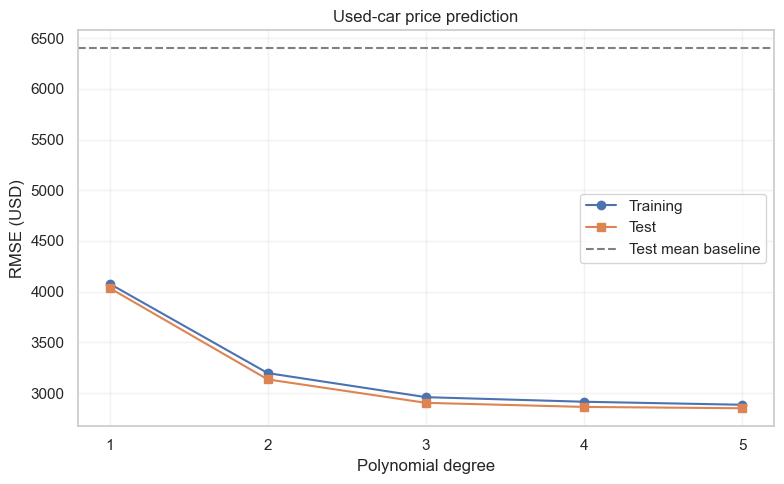

In [10]:
baseline_train = rmse(Y_train, np.full(len(Y_train), Y_train.mean()))
baseline_test = rmse(Y_test, np.full(len(Y_test), Y_train.mean()))
records = []
for degree in DEGREES:
    phi_train = design_matrix(X_train, degree)
    phi_test = design_matrix(X_test, degree)
    if phi_train.shape[1] >= len(Y_train):
        raise ValueError('Reduce degree or feature count to keep an overdetermined system.')
    weights, rank = fit_batch(phi_train, Y_train)
    records.append({'degree': degree, 'basis_columns': phi_train.shape[1],
                    'rank': rank, 'train_sse': sse(Y_train, phi_train @ weights),
                    'test_sse': sse(Y_test, phi_test @ weights),
                    'train_rmse_usd': rmse(Y_train, phi_train @ weights),
                    'test_rmse_usd': rmse(Y_test, phi_test @ weights)})
results = pd.DataFrame(records)
display(results.round(3))
print(f'Mean baseline RMSE — training USD {baseline_train:,.2f}, test USD {baseline_test:,.2f}')
results.to_csv('used_cars_results.csv', index=False)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(results.degree, results.train_rmse_usd, 'o-', label='Training')
ax.plot(results.degree, results.test_rmse_usd, 's-', label='Test')
ax.axhline(baseline_test, color='gray', linestyle='--', label='Test mean baseline')
ax.set(xlabel='Polynomial degree', ylabel='RMSE (USD)',
       title='Used-car price prediction', xticks=DEGREES)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig('used_cars_rmse.png', dpi=180)
plt.show()


## Interpret the measured results
Training error should generally fall as degree increases because the higher-degree space includes the lower-degree functions. Test error can increase if the additional terms fit noise or extrapolate poorly. Large errors may also reflect omitted manufacturer/model information, unusual vehicles or a skewed price distribution. The following text reports the actual run and compares it with the mean baseline.

In [15]:
best = results.loc[results.test_rmse_usd.idxmin()]
last = results.iloc[-1]
first = results.iloc[0]
print(f'Lowest observed test RMSE: USD {best.test_rmse_usd:,.2f} at degree {int(best.degree)}.')
print(f'Training RMSE at that degree: USD {best.train_rmse_usd:,.2f}.')
print(f'Baseline improvement: USD {baseline_test - best.test_rmse_usd:,.2f} '
      f'({100 * (baseline_test - best.test_rmse_usd) / baseline_test:.1f}%).')
print(f'Degree 1 to {int(last.degree)}: training RMSE changes from '
      f'USD {first.train_rmse_usd:,.2f} to USD {last.train_rmse_usd:,.2f}; '
      f'test RMSE changes from USD {first.test_rmse_usd:,.2f} to USD {last.test_rmse_usd:,.2f}.')
if last.test_rmse_usd > best.test_rmse_usd:
    print('The highest degree generalizes worse than the degree with the lowest observed test error.')



Lowest observed test RMSE: USD 2,850.30 at degree 5.
Training RMSE at that degree: USD 2,884.81.
Baseline improvement: USD 3,547.93 (55.5%).
Degree 1 to 5: training RMSE changes from USD 4,078.44 to USD 2,884.81; test RMSE changes from USD 4,036.29 to USD 2,850.30.


## Actual and predicted prices
This diagnostic uses degree 1 as a fixed reference model. Points near the diagonal have small prediction errors. Negative predictions are possible with unconstrained least squares.

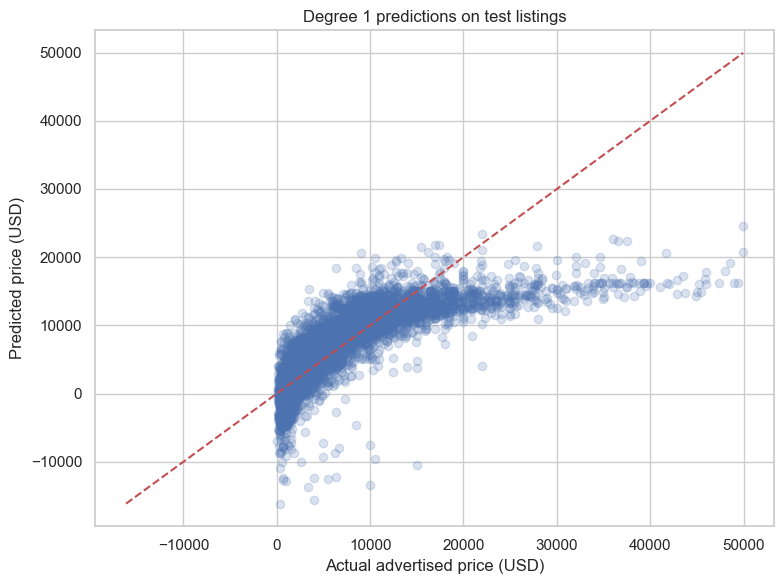

In [ ]:
reference_degree = 1
reference_matrix = design_matrix(X_train, reference_degree)
reference_weights, _ = fit_batch(reference_matrix, Y_train)
predicted = design_matrix(X_test, reference_degree) @ reference_weights
plt.figure(figsize=(8,6))
plt.scatter(Y_test, predicted, alpha=0.2)
limits = [min(Y_test.min(), predicted.min()), max(Y_test.max(), predicted.max())]
plt.plot(limits, limits, 'r--')
plt.xlabel('real price (USD)')
plt.ylabel('predicted price (USD)')
plt.title('Degree 1 predictions on test listings')
plt.tight_layout()
plt.show()

Going from degree 1 to degree 2 lowered that score by about $902. Going from degree 4 to degree 5 lowered it by only $13.